# E-Commerce Customer Segmentation and Retention Strategy (RFM)

**Academic project.** Customer segmentation of a UK-based online retailer using RFM (Recency, Frequency, Monetary) analysis in Python.

**Data:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) (Daqing Chen, 2015, [doi:10.24432/C5BW33](https://doi.org/10.24432/C5BW33), CC BY 4.0). 541,909 line items from 01 Dec 2010 to 09 Dec 2011. The raw file is not stored in this repository; the first cell downloads it.

**Pipeline**
1. Data engineering and cleaning
2. RFM matrix
3. Quintile scoring and marketing segments
4. Business KPIs: VIP concentration, 180-day churn risk, average order value by purchase frequency
5. Visual storytelling

In [1]:
import datetime as dt
import io
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
IMAGES_DIR = ROOT / 'images'
OUTPUT_DIR = ROOT / 'outputs'
for folder in (DATA_DIR, IMAGES_DIR, OUTPUT_DIR):
    folder.mkdir(exist_ok=True)

DATA_FILE = DATA_DIR / 'online_retail.csv'
UCI_URL = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'

def download_online_retail(target=DATA_FILE, url=UCI_URL):
    """Download the UCI Online Retail workbook and save it as CSV."""
    with urllib.request.urlopen(url) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    with archive.open('Online Retail.xlsx') as workbook:
        raw = pd.read_excel(workbook, dtype={'InvoiceNo': str, 'StockCode': str})
    raw.to_csv(target, index=False)

if not DATA_FILE.exists():
    download_online_retail()

df = pd.read_csv(DATA_FILE, dtype={'InvoiceNo': str, 'StockCode': str})
print(f'Raw line items: {len(df):,}')
df.head()

Raw line items: 541,909


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Phase 1: Data engineering and cleaning

Steps, in order:
1. Recover missing `CustomerID` and `Country` values from other lines of the same invoice, then drop rows that still have no customer and exact duplicates.
2. Parse `InvoiceDate`.
3. Remove cancellations (invoice numbers starting with `C`, negative quantities) and non-positive prices (free samples, accounting adjustments). This happens **before** the RFM matrix so these rows cannot distort Frequency or Monetary.
4. Cap extreme quantities at the 99th percentile so a few bulk lines do not skew averages.
5. Compute line-item revenue (`TotalMoney`).

In [2]:
def recover_from_invoice(dataframe, key_col, value_col):
    """Fill missing values using another line of the same invoice."""
    mapping = (dataframe.dropna(subset=[value_col])
               .drop_duplicates(key_col)
               .set_index(key_col)[value_col])
    dataframe[value_col] = dataframe[value_col].fillna(dataframe[key_col].map(mapping))
    return dataframe

df = recover_from_invoice(df, 'InvoiceNo', 'CustomerID')
df = recover_from_invoice(df, 'InvoiceNo', 'Country')
df_clean = df.dropna(subset=['CustomerID']).drop_duplicates()
print(f'With a CustomerID, no duplicates: {len(df_clean):,}')

df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], errors='coerce')
df_clean = df_clean.dropna(subset=['InvoiceDate']).sort_values('InvoiceDate')

is_cancellation = df_clean['InvoiceNo'].str.startswith('C') | (df_clean['Quantity'] <= 0)
print(f'Cancellation / return lines removed: {is_cancellation.sum():,}')
df_clean = df_clean[~is_cancellation]

non_positive_price = df_clean['UnitPrice'] <= 0
print(f'Non-positive price lines removed: {non_positive_price.sum():,}')
df_clean = df_clean[~non_positive_price]

quantity_cap = df_clean['Quantity'].quantile(0.99)
print(f'99th percentile quantity cap: {quantity_cap:.0f} units')
df_clean = df_clean[df_clean['Quantity'] <= quantity_cap].copy()

df_clean['TotalMoney'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
print(f'Clean line items: {len(df_clean):,} | customers: {df_clean.CustomerID.nunique():,}')
print(f'Period: {df_clean.InvoiceDate.min():%d %b %Y} to {df_clean.InvoiceDate.max():%d %b %Y}')

With a CustomerID, no duplicates: 401,604
Cancellation / return lines removed: 8,872
Non-positive price lines removed: 40
99th percentile quantity cap: 120 units
Clean line items: 388,804 | customers: 4,303
Period: 01 Dec 2010 to 09 Dec 2011


## Phase 2: RFM matrix

The reference date is one day after the newest invoice.
- **Recency:** days since the customer's last purchase
- **Frequency:** number of distinct invoices
- **Monetary:** total revenue

In [3]:
reference_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)

rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalMoney': 'sum',
})
rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm.describe().round(2)

,Recency,Frequency,Monetary
count,4303.00,4303.00,4303.00
mean,92.66,4.22,1672.42
std,100.05,7.54,5047.02
min,1.00,1.00,2.90
25%,18.00,1.00,300.03
50%,51.00,2.00,650.32
75%,143.00,5.00,1593.18
max,374.00,209.00,160824.60


## Phase 3: Scoring and segmentation

Each dimension is scored 1 to 5 by quintile (Recency is inverted: fewer days means a higher score). The three scores add up to an RFM score between 3 and 15, which maps to five marketing segments.

In [4]:
rfm['R'] = pd.qcut(rfm['Recency'], q=5, labels=range(5, 0, -1))
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=range(1, 6))
rfm['M'] = pd.qcut(rfm['Monetary'], q=5, labels=range(1, 6))
rfm['RFM_Score'] = rfm['R'].astype(int) + rfm['F'].astype(int) + rfm['M'].astype(int)

def classify_clients(score):
    if score >= 14: return 'Champions'
    elif score >= 12: return 'Loyal Customers'
    elif score >= 8: return 'Potential Loyalists'
    elif score >= 6: return 'In Risk'
    else: return 'Lost'

rfm['Segment'] = rfm['RFM_Score'].apply(classify_clients)

segment_order = ['Champions', 'Loyal Customers', 'Potential Loyalists', 'In Risk', 'Lost']
total_sales = rfm['Monetary'].sum()
total_clients = len(rfm)

segment_summary = (rfm.groupby('Segment')
                   .agg(Customers=('Monetary', 'size'),
                        Revenue=('Monetary', 'sum'),
                        Avg_Recency_days=('Recency', 'mean'),
                        Avg_Orders=('Frequency', 'mean'))
                   .reindex(segment_order))
segment_summary['Customer_share_%'] = 100 * segment_summary['Customers'] / total_clients
segment_summary['Revenue_share_%'] = 100 * segment_summary['Revenue'] / total_sales
segment_summary.round(1)

,Customers,Revenue,Avg_Recency_days,Avg_Orders,Customer_share_%,Revenue_share_%
Segment,,,,,,
Champions,651,4112748.7,10.5,13.7,15.1,57.1
Loyal Customers,599,1234014.6,28.6,5.5,13.9,17.1
Potential Loyalists,1382,1324626.4,63.7,2.8,32.1,18.4
In Risk,797,332058.4,112.7,1.4,18.5,4.6
Lost,874,192982.0,225.3,1.0,20.3,2.7


In [5]:
# Export customer-level and line-level datasets for BI dashboards (not committed to git)
df_ready = df_clean.merge(rfm[['Segment', 'RFM_Score']], left_on='CustomerID', right_index=True, how='left')
df_ready.to_csv(OUTPUT_DIR / 'df_ready_to_analyze.csv', index=False)
rfm.to_csv(OUTPUT_DIR / 'rfm_final_segmentation.csv')
print('Exported: outputs/df_ready_to_analyze.csv | outputs/rfm_final_segmentation.csv')

Exported: outputs/df_ready_to_analyze.csv | outputs/rfm_final_segmentation.csv


## Phase 4: Business KPIs

In [6]:
# Insight 1: VIP revenue concentration
vips = rfm[rfm['Segment'] == 'Champions']
sales_vips, n_vips = vips['Monetary'].sum(), len(vips)
print(f'Champions: {n_vips:,} customers ({100*n_vips/total_clients:.1f}% of base) '
      f'generate ${sales_vips:,.0f} ({100*sales_vips/total_sales:.1f}% of revenue)')

# Insight 2: churn risk (no purchase in more than 180 days)
clients_at_risk = rfm[rfm['Recency'] > 180]
money_at_risk, n_risk = clients_at_risk['Monetary'].sum(), len(clients_at_risk)
print(f'At risk (>180 days inactive): {n_risk:,} customers ({100*n_risk/total_clients:.1f}%) '
      f'holding ${money_at_risk:,.0f} ({100*money_at_risk/total_sales:.1f}% of revenue)')

# Insight 3: average order value (AOV) of very frequent buyers
rfm['Average_Order_Value'] = rfm['Monetary'] / rfm['Frequency']
threshold_freq = 12
hyper_freq = rfm[rfm['Frequency'] > threshold_freq]
normal_group = rfm[rfm['Frequency'] <= threshold_freq]
aov_hyper = hyper_freq['Average_Order_Value'].mean()
aov_normal = normal_group['Average_Order_Value'].mean()
print(f'Customers with more than {threshold_freq} orders: {len(hyper_freq):,} | '
      f'mean AOV ${aov_hyper:,.2f} vs ${aov_normal:,.2f} for everyone else '
      f'({aov_hyper/aov_normal:.2f}x)')

Champions: 651 customers (15.1% of base) generate $4,112,749 (57.1% of revenue)
At risk (>180 days inactive): 856 customers (19.9%) holding $411,542 (5.7% of revenue)
Customers with more than 12 orders: 234 | mean AOV $459.25 vs $348.62 for everyone else (1.32x)


## Phase 5: Visual storytelling

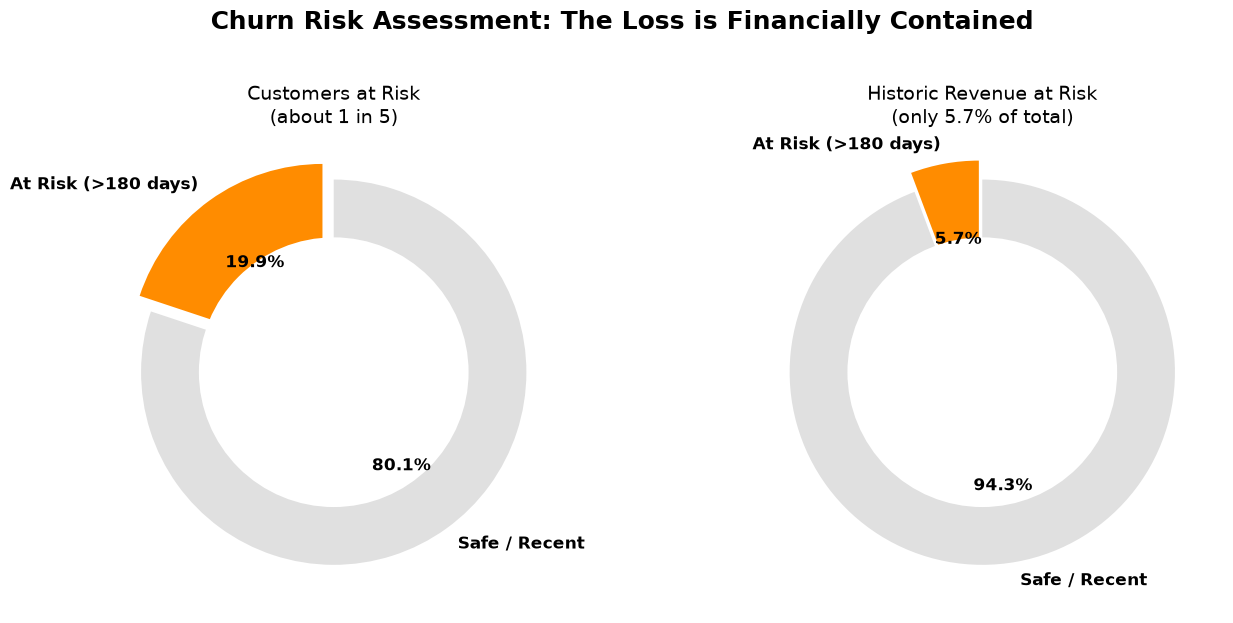

In [7]:
def donut_pair(values_left, values_right, labels, colors, titles, suptitle, path):
    explode = (0.1, 0)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    for ax, values, title in ((ax1, values_left, titles[0]), (ax2, values_right, titles[1])):
        ax.pie(values, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
               startangle=90, textprops={'fontsize': 12, 'weight': 'bold'})
        ax.add_artist(plt.Circle((0, 0), 0.70, fc='white'))
        ax.set_title(title, fontsize=14)
    fig.suptitle(suptitle, fontsize=18, fontweight='bold', y=1.03)
    fig.tight_layout()
    fig.savefig(path, dpi=120, bbox_inches='tight')
    plt.show()

risk_share = n_risk / total_clients
money_risk_share = money_at_risk / total_sales
donut_pair([n_risk, total_clients - n_risk],
           [money_at_risk, total_sales - money_at_risk],
           ['At Risk (>180 days)', 'Safe / Recent'], ['#FF8C00', '#E0E0E0'],
           [f'Customers at Risk\n(about 1 in {round(1/risk_share)})',
            f'Historic Revenue at Risk\n(only {100*money_risk_share:.1f}% of total)'],
           'Churn Risk Assessment: The Loss is Financially Contained',
           IMAGES_DIR / 'churn-risk.png')

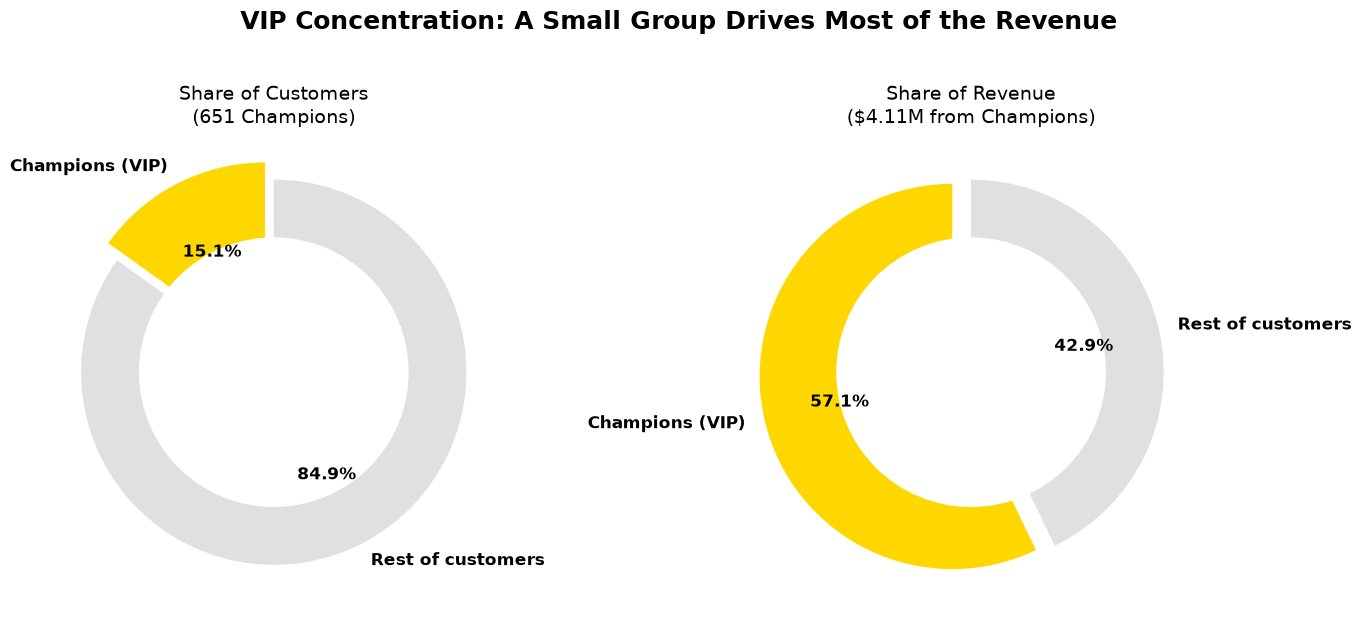

In [8]:
donut_pair([n_vips, total_clients - n_vips],
           [sales_vips, total_sales - sales_vips],
           ['Champions (VIP)', 'Rest of customers'], ['#FFD700', '#E0E0E0'],
           [f'Share of Customers\n({n_vips:,} Champions)',
            f'Share of Revenue\n(${sales_vips/1e6:.2f}M from Champions)'],
           'VIP Concentration: A Small Group Drives Most of the Revenue',
           IMAGES_DIR / 'vip-pareto.png')

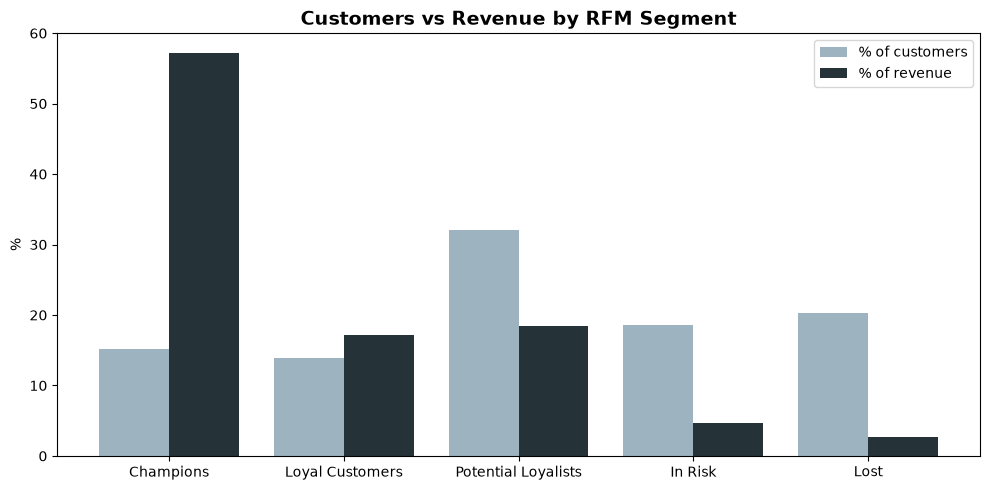

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(segment_order))
ax.bar(x - 0.2, segment_summary['Customer_share_%'], width=0.4, label='% of customers', color='#9DB4C0')
ax.bar(x + 0.2, segment_summary['Revenue_share_%'], width=0.4, label='% of revenue', color='#253237')
ax.set_xticks(x, segment_order)
ax.set_ylabel('%')
ax.set_title('Customers vs Revenue by RFM Segment', fontsize=14, fontweight='bold')
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES_DIR / 'segment-share.png', dpi=120, bbox_inches='tight')
plt.show()

## Recommendations

- **Protect the Champions.** They are the smallest group with the largest share of revenue. Priority service, early access, and loyalty rewards are cheaper than replacing that revenue.
- **Win back selectively.** Customers inactive for more than 180 days are a large share of the base but a small share of revenue. Run low-cost automated win-back campaigns rather than expensive one-to-one outreach.
- **Grow Potential Loyalists.** The biggest segment by headcount; second-purchase incentives move them toward Loyal.
- **Next step:** a Tableau or Power BI dashboard on top of the exported `rfm_final_segmentation.csv`, plus cohort retention curves.